In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import string
from scipy.stats import pearsonr
from nltk.corpus import stopwords
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Ted Talks Recommendation System/tedx_dataset.csv')
df.head()

,idx,main_speaker,title,details,posted,url,num_views
0,8d2005ec35280deb6a438dc87b225f89,Alexandra Auer,The intangible effects of walls,More barriers exist now than at the end of Wor...,Posted Apr 2020,https://www.ted.com/talks/alexandra_auer_the_i...,NaN
1,b3072cd11f40eb57fd259555264476c6,Elizabeth Gilbert,It's OK to feel overwhelmed. Here's what to do...,If you're feeling anxious or fearful during th...,Posted Apr 2020,https://www.ted.com/talks/elizabeth_gilbert_it...,NaN
2,4adc9fee977fa04c357ed4c9b52aa3cc,Butterscotch,"""Accept Who I Am""","Firing off her formidable beatboxing skills, m...",Posted Apr 2020,https://www.ted.com/talks/butterscotch_accept_...,0.0
3,59c641a72b495d522a7932145d6c02b3,Ethan Lisi,What it's really like to have autism,"""Autism is not a disease; it's just another wa...",Posted Apr 2020,https://www.ted.com/talks/ethan_lisi_what_it_s...,NaN
4,d227f2faf6ec185e54436d86463f499b,Daniel Finkel,Can you solve the sea monster riddle?,"According to legend, once every thousand years...",Posted Apr 2020,https://www.ted.com/talks/daniel_finkel_can_yo...,0.0


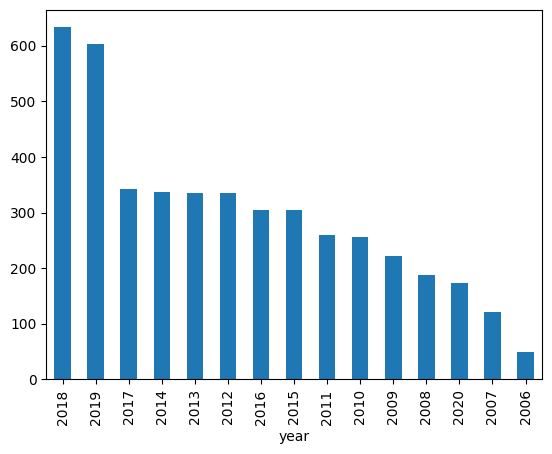

In [ ]:
splitted_date = df['posted'].str.split(' ', expand=True)
df['month'] = splitted_date[1]
df['year'] = splitted_date[2]
df['year'].value_counts().plot.bar()
plt.show()

In [ ]:
df['details'] = df['title'] + ' ' + df['details']
df = df[['main_speaker', 'details']]
df.dropna(inplace=True)
df.head()

,main_speaker,details
0,Alexandra Auer,The intangible effects of walls More barriers ...
1,Elizabeth Gilbert,It's OK to feel overwhelmed. Here's what to do...
2,Butterscotch,"""Accept Who I Am"" Firing off her formidable be..."
3,Ethan Lisi,"What it's really like to have autism ""Autism i..."
4,Daniel Finkel,Can you solve the sea monster riddle? Accordin...


In [ ]:
data = df.copy()

def remove_stopwords(text):
    stop_words = set(stopwords.words('english'))

    important_words = []
    for word in str(text).split():
        word = word.lower()

        if word not in stop_words:
            important_words.append(word)

    return ' '.join(important_words)

df['details'] = df['details'].apply(lambda text: remove_stopwords(text))
df.head()

,main_speaker,details
0,Alexandra Auer,intangible effects walls barriers exist end wo...
1,Elizabeth Gilbert,ok feel overwhelmed. here's next feeling anxio...
2,Butterscotch,"""accept am"" firing formidable beatboxing skill..."
3,Ethan Lisi,"really like autism ""autism disease; another wa..."
4,Daniel Finkel,"solve sea monster riddle? according legend, ev..."


In [ ]:
punctuations = string.punctuation

def clean_punctuations(text):
  signal = str.maketrans('', '', punctuations)
  return text.translate(signal)

df['details'] = df['details'].apply(lambda text: clean_punctuations(text))
df.head()

,main_speaker,details
0,Alexandra Auer,intangible effects walls barriers exist end wo...
1,Elizabeth Gilbert,ok feel overwhelmed heres next feeling anxious...
2,Butterscotch,accept am firing formidable beatboxing skills ...
3,Ethan Lisi,really like autism autism disease another way ...
4,Daniel Finkel,solve sea monster riddle according legend ever...


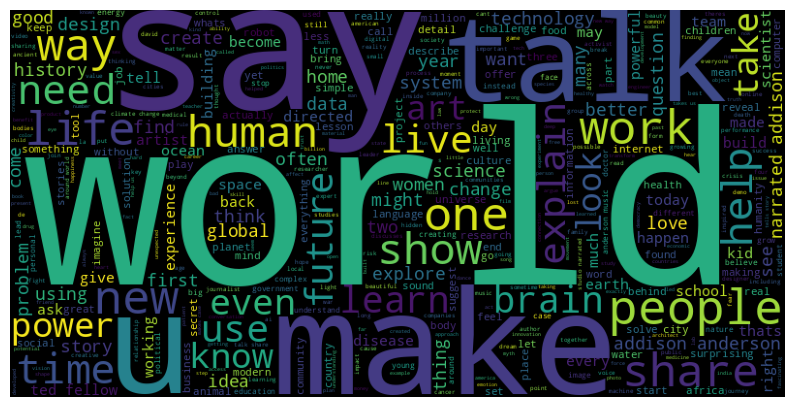

In [ ]:
corpus = ' '.join(df['details'])

plt.figure(figsize=(10, 10))
plt.imshow(WordCloud(max_words=1000, width=800, height=400).generate(corpus))
plt.axis('off')
plt.show()

In [ ]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit(df['details'])

In [ ]:
def get_similar_talks(talk_content, data=df):
  talk_vector1 = vectorizer.transform([talk_content]).toarray()

  cos_sim = []
  pea_sim = []
  for idx, row in data.iterrows():
    details = row['details']
    talk_vector2 = vectorizer.transform(data[data['details'] == details]['details']).toarray()

    cos_sim.append(cosine_similarity(talk_vector1, talk_vector2)[0][0])
    pea_sim.append(pearsonr(talk_vector1.squeeze(),talk_vector2.squeeze())[0])

  return cos_sim, pea_sim

def recommend_talks(talk_content, data=data):
  data['cos_sim'], data['pea_sim'] = get_similar_talks(talk_content)
  data.sort_values(by=['cos_sim', 'pea_sim'], ascending=[False, False], inplace=True)
  display(data[['main_speaker', 'details']].head(10))

In [ ]:
talk_content = 'Time Management and working hard to become successful in life'
recommend_talks(talk_content)

,main_speaker,details
1758,Laura Vanderkam,How to gain control of your free time There ar...
2173,Philip Krinks,Finding your personal mission in life Philip K...
66,Fang Ruan,Management lessons from Chinese business and p...
2075,Jessica Shortall,The US needs paid family leave — for the sake ...
2446,Susan Etlinger,What do we do with all this big data? Does a s...
1658,Chimamanda Ngozi Adichie,We should all be feminists We teach girls that...
3190,Nirmalya Kumar,India's invisible innovation Can India become ...
3889,Steven Cowley,Fusion is energy's future Physicist Steven Cow...
3440,Christoph Adami,Finding life we can't imagine How do we search...
1687,Karina Galperin,Should we simplify spelling? How much energy a...
